# Travel Booking Fraud Review – CRISP-DM
**Course:** Data Science for Business (DATDRD05-T03) · **Group 7 – Fraud 3** · Alberto Barrionuevo Vargas-Machuca, Anisah Sutrisno, Kyran Weijman

Dataset: **group_07_fraud_3.csv**.

**Convention used throughout:** we label each statement as **[Scenario]** (given by the case, not verified), **[Data]** (shown by visible code/output) or **[Choice]** (our own analytical decision).

## Phase 1 – Business Understanding

### 1.1 Business problem
**[Scenario]** A travel booking business wants to find fraudulent bookings/transactions. Fraud is rare, and each fraudulent booking leads to losses after it is investigated. The business cannot manually review every transaction, so it needs a way to prioritise which transactions are reviewed first.

### 1.2 Stakeholder / user
- Primary user: the fraud review team (analysts who open the cases and decide).
- Decision owner: fraud/risk manager (sets the review capacity and accepts the trade-off between cost of review and fraud losses).
- Affected: genuine customers (a false alarm means delay, friction or a blocked booking) and finance (fraud losses, chargebacks).

### 1.3 Decision
For each new transaction: send it to manual review, or let it go through automatically. The model does not decide fraud; it ranks transactions so that limited review time goes to the riskiest ones.

### 1.4 Prediction / decision moment
Right after a booking transaction is made and before it is confirmed/fulfilled. Only information known at that moment can be used (amount, customer history, account age, channel, country, hour, device age, recent activity).
Information that appears after the decision is not available then, so it cannot be a predictor (candidate leakage, to be verified in Phase 2).

### 1.5 Scope
- In scope: one binary prediction (fraud_flag: fraud / not fraud) for transactions in the supplied dataset, producing a risk score and a review list.
- Out of scope: automatic blocking of customers, legal/chargeback process, building the investigation workflow, causes of fraud beyond what the data shows.

### 1.6 Measurable success criteria
Accuracy is not a valid criterion: with very few frauds, a model that says "everything is legitimate" is almost always "right".
We will judge success against a baseline, using review capacity:
1. Primary: share of all fraud cases found in the top *X*% highest-risk transactions (recall at top *X*% review capacity), compared with the baseline "no model" (random review finds about *X*% of fraud) and a majority-class baseline (finds none).
2. Secondary: ROC AUC (ranking quality) and precision at the same cutoff (how many reviewed cases are really fraud; workload and customer friction).
3. Stability: the cutoff must behave similarly in train and test (e.g. share of transactions above the threshold does not change a lot).
4. Minimum bar for use: clearly better than random review on the test set.Review capacity assumption [Choice]: the case gives no real capacity, so we state one: the team can manually review 5% of transactions (X = 5). Why 5%: the brief asks us to evaluate under a stated capacity; the fraud rate in the file is 32/3,203 = around 1.0%, so 5% is about five times the fraud rate, enough room to include fraud plus false alarms, but still a real limit; in a test set of about 960 rows, 5% is about 48 reviews. For robustness we will also report 2% and 10%.

### 1.7 Costs of errors (business view)
- Missed fraud (false negative): direct financial loss, possible chargeback, reputational damage.
- False alarm (false positive): analyst time wasted and a genuine customer delayed or annoyed.
- With 1% fraud, even a good model produces many false alarms per real fraud found, so the review capacity limit matters more than a single "accuracy" number.
- No real cost figures are given. We will not invent them, we will compare alternatives qualitatively or with clearly labelled assumptions.

### 1.8 Critical assessment of scenario assumptions
| Assumption in the scenario | Why it may be wrong / limited | How we handle it |
|---|---|---|
| The label fraud_flag equals true fraud | It may only reflect cases that were detected/investigated; undetected fraud is labelled legitimate | Treat results as "detected fraud"; mention as limitation |
| Data is about travel bookings | [Data (to be shown in Phase 2)] first inspection suggests the columns are generic payment/account fields, none seems to describe a trip . Evidence (df.columns) is shown in Phase 2 | Until then, do not claim travel-specific patterns (confirm in Phase 2) |
| Past patterns will repeat | Fraudsters adapt, the model can age quickly | Monitoring and refresh in Phase 6 |
| Manual review is possible for some fraction | The real capacity and cost per review are unknown | State an assumed *X*% and test sensitivity |
| Post-investigation fields are usable | They are only known after the decision: leakage | Exclude them from predictors, justify with evidence in Phase 2 |
| Very few fraud cases | Results can be unstable (a handful of cases changes recall a lot) | Stratified split, report counts not only percentages, be cautious in claims |


## Phase 2 – Data Understanding
**Goal**: know what one row is, what the target is, how reliable the data is, which patterns exist and which columns must not be used. Every number quoted in the text comes from a visible cell below.

### 2.1 Load the data and first look

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

df = pd.read_csv('group_07_fraud_3.csv')
print('Shape (rows, columns):', df.shape)
print('\nColumns:', list(df.columns))
print('\nData types:')
print(df.dtypes)
df.head()

Shape (rows, columns): (3203, 12)

Columns: ['transaction_id', 'amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'channel', 'country', 'hour', 'device_age_days', 'fraud_flag', 'post_investigation_loss_eur', 'chargeback_confirmed_after_60d']

Data types:
transaction_id                        str
amount_eur                        float64
customer_avg_amount_30d           float64
account_age_days                    int64
previous_transactions_24h           int64
channel                               str
country                               str
hour                                int64
device_age_days                     int64
fraud_flag                          int64
post_investigation_loss_eur       float64
chargeback_confirmed_after_60d      int64
dtype: object


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
0,TX30000000,29.40,38.19,1721,6,Online,ES,17,930,0,0.0,0
1,TX30000001,85.71,81.98,1731,3,app,DE,5,326,0,0.0,0
2,TX30000002,45.36,180.96,2098,2,app,DE,17,1030,0,0.0,0
3,TX30000003,72.43,61.92,1646,2,online,NL,15,594,0,0.0,0
4,TX30000004,94.67,45.00,833,2,app,FR,22,202,0,0.0,0


Variable dictionary. No data dictionary was supplied, so the meanings below are **[Assumption]** inferred from the column names, not verified facts.

| Column | Assumed meaning | Type | Known at decision moment? |
|---|---|---|---|
| transaction_id | Identifier of the transaction | text (key) | Yes, identifier only, not a predictor |
| amount_eur | Transaction amount in EUR | numeric | Yes |
| customer_avg_amount_30d | Customer's average amount over the previous 30 days | numeric | Yes, if it excludes the current transaction (to be assumed, cannot be checked) |
| account_age_days | Age of the account in days | numeric | Yes |
| previous_transactions_24h | Number of transactions in the previous 24 h | numeric | Yes, if it excludes the current one |
| channel | Sales channel (online / app / store) | categorical | Yes |
| country | Country code (ES, BE, FR, DE, NL, UK) | categorical | Yes |
| hour | Hour of the day (0–23) | numeric | Yes |
| device_age_days | Age of the device in days | numeric | Yes |
| fraud_flag | Target: 1 = fraud, 0 = legitimate | binary | No, it is the outcome |
| post_investigation_loss_eur | Loss recorded after investigation | numeric | No, by name, it exists only after the investigation |
| chargeback_confirmed_after_60d | Chargeback confirmed 60 days later | binary | No, by name, it is known only 60 days later |

Evidence for the travel assumption from Phase 1: the column list above contains no trip-related field. The data describe generic payment/account behaviour, so we treat the problem as transaction fraud and will not claim travel-specific findings.

### 2.2 Observation unit, key and target

In [2]:
# Key: is transaction_id unique?
print('Rows:', len(df))
print('Unique transaction_id:', df['transaction_id'].nunique())
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicated transaction_id:', df['transaction_id'].duplicated().sum())

print('\nRows whose transaction_id appears more than once:')
display(df[df['transaction_id'].duplicated(keep=False)].sort_values('transaction_id'))

# Target
print('Target fraud_flag (counts):')
print(df['fraud_flag'].value_counts())
print('\nFraud rate: %.2f%%' % (100 * df['fraud_flag'].mean()))
print('Legitimate per fraud case: %.0f' % ((df['fraud_flag'] == 0).sum() / df['fraud_flag'].sum()))

Rows: 3203
Unique transaction_id: 3200
Fully duplicated rows: 3
Duplicated transaction_id: 3

Rows whose transaction_id appears more than once:


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
476,TX30000476,52.36,36.28,260,3,app,FR,19,1064,0,0.0,0
3201,TX30000476,52.36,36.28,260,3,app,FR,19,1064,0,0.0,0
2597,TX30002597,25.42,45.31,1592,2,online,DE,2,31,0,0.0,0
3200,TX30002597,25.42,45.31,1592,2,online,DE,2,31,0,0.0,0
3052,TX30003052,226.00,72.10,2100,1,app,DE,1,199,0,0.0,0
3202,TX30003052,226.00,72.10,2100,1,app,DE,1,199,0,0.0,0


Target fraud_flag (counts):
fraud_flag
0    3171
1      32
Name: count, dtype: int64

Fraud rate: 1.00%
Legitimate per fraud case: 99


**What the output shows**
- Observation unit: one row = one transaction (booking payment). Key: transaction_id.
- The key is not perfectly unique: 3,203 rows but 3,200 unique IDs. The 3 repeated IDs (TX30000476, TX30002597, TX30003052) are exact copies of an earlier row, and the copies sit at the very end of the file, so they look like accidental duplicates, not new transactions. All 3 are legitimate. Duplicates would count the same event twice, so they will be removed in Phase 3.
- Target: 32 frauds vs 3,171 legitimate = 1.00% (about 99 legitimate per fraud). This is a strong rare event problem. A model that always says "legitimate" would be 99.0% accurate and find 0 frauds, confirming why accuracy is not our metric.
- Limitation: 32 positives is very few. Any rate, split or metric based on them will be noisy.

### 2.3 Data quality: missing, invalid and inconsistent values

In [3]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])

print('\nMissing amount_eur by class (share of each class):')
print(df.assign(amount_missing=df['amount_eur'].isna()).groupby('fraud_flag')['amount_missing'].agg(['sum', 'mean']))

print('\nImpossible values:')
print('amount_eur <= 0           :', (df['amount_eur'] <= 0).sum())
print('account_age_days < 0      :', (df['account_age_days'] < 0).sum())
print('device_age_days < 0       :', (df['device_age_days'] < 0).sum())
print('hour outside 0-23         :', (~df['hour'].between(0, 23)).sum())
print('Rows with account_age_days < 0:')
display(df[df['account_age_days'] < 0])

print('\nchannel – raw labels:')
print(df['channel'].value_counts())
print('\nchannel – after lower-case + strip:')
print(df['channel'].str.lower().str.strip().value_counts())

print('\ncountry labels:')
print(df['country'].value_counts())

Missing values per column:
amount_eur    20
dtype: int64

Missing amount_eur by class (share of each class):
            sum      mean
fraud_flag               
0            19  0.005992
1             1  0.031250

Impossible values:
amount_eur <= 0           : 0
account_age_days < 0      : 4
device_age_days < 0       : 0
hour outside 0-23         : 0
Rows with account_age_days < 0:


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
183,TX30000183,50.52,36.56,-27,2,store,FR,15,314,0,0.0,0
348,TX30000348,656.76,33.12,-20,3,store,BE,8,936,0,0.0,0
2118,TX30002118,114.76,32.47,-27,0,app,FR,17,755,0,0.0,0
2170,TX30002170,34.90,38.29,-28,3,store,FR,9,264,0,0.0,0



channel – raw labels:
channel
app       1019
online     948
store      636
Online     280
APP        219
ONLINE     101
Name: count, dtype: int64

channel – after lower-case + strip:
channel
online    1329
app       1238
store      636
Name: count, dtype: int64

country labels:
country
ES    580
BE    569
FR    526
DE    517
NL    514
UK    497
Name: count, dtype: int64


**What the output shows**
- Missing values: only "amount_eur" (20 rows, 0.6%). It is the most important variable, so we must not ignore it. 1 of the 20 is a fraud case 3.1% versus (0.6%) among legitimate rows. With a single fraud case we cannot conclude that missingness is related to fraud, but we also cannot rule it out, so Phase 3 should keep an indicator of missingness or at least check it.
- Impossible values: 4 rows have a negative "account_age_days" (−20 to −28), which is impossible for an account age. All 4 are legitimate. Likely an entry or timing error. No other impossible values (no amount ≤ 0, hours all in 0–23, no negative device age).
- Inconsistent categories: "channel" has 6 labels for 3 real channels (Online, ONLINE, online; APP, app; store). After lower-casing: online 1,329, app 1,238, store 636. Without cleaning, a model would treat "app" and "APP" as different channels.
- "country" is clean (6 consistent codes).

### 2.4 Distributions of the numeric variables

                            count     mean     std    min     25%      50%      75%      max
amount_eur                 3183.0   100.03  119.30   1.72   30.58    61.46   119.48  1698.57
customer_avg_amount_30d    3203.0    61.47   44.16   4.99   32.43    49.19    77.07   436.78
account_age_days           3203.0  1251.24  718.61 -28.00  633.00  1253.00  1877.50  2498.00
previous_transactions_24h  3203.0     2.39    1.57   0.00    1.00     2.00     3.00    10.00
hour                       3203.0    11.45    6.85   0.00    6.00    12.00    17.00    23.00
device_age_days            3203.0   587.97  350.39   0.00  289.00   576.00   898.00  1199.00

Skewness (0 = symmetric):
amount_eur                   3.63
customer_avg_amount_30d      2.12
account_age_days             0.01
previous_transactions_24h    0.67
hour                        -0.02
device_age_days              0.04
dtype: float64

amount_eur IQR upper fence: 252.8
Rows above the fence: 248
Fraud cases above the fence: 6 of 32


Text(0.5, 0, 'hour')

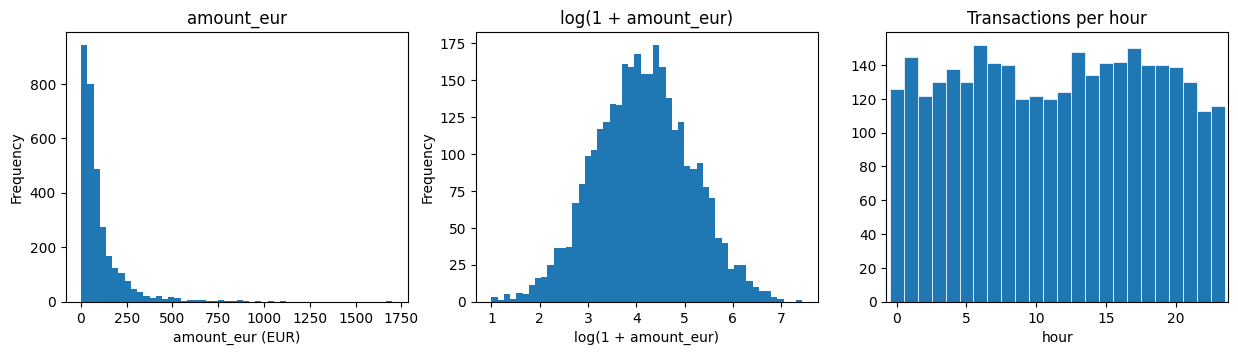

In [4]:
num_cols = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days',
            'previous_transactions_24h', 'hour', 'device_age_days']
print(df[num_cols].describe().T.round(2))
print('\nSkewness (0 = symmetric):')
print(df[num_cols].skew().round(2))

# Outliers in amount_eur with the IQR rule
q1, q3 = df['amount_eur'].quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
print('\namount_eur IQR upper fence: %.1f' % upper)
print('Rows above the fence:', (df['amount_eur'] > upper).sum())
print('Fraud cases above the fence:', ((df['amount_eur'] > upper) & (df['fraud_flag'] == 1)).sum(), 'of', df['fraud_flag'].sum())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))

df['amount_eur'].plot.hist(bins=50, ax=ax[0], title='amount_eur')
ax[0].set_xlabel('amount_eur (EUR)')

np.log1p(df['amount_eur']).plot.hist(bins=50, ax=ax[1], title='log(1 + amount_eur)')
ax[1].set_xlabel('log(1 + amount_eur)')

# One bar per hour, bars touching, x-axis labels every 5 hours starting at 0
df['hour'].value_counts().sort_index().plot.bar(ax=ax[2], width=1.0, edgecolor='white', linewidth=0.5,
                                                title='Transactions per hour')
ax[2].set_xticks(range(0, 24, 5))
ax[2].set_xticklabels(range(0, 24, 5), rotation=0)
ax[2].set_xlabel('hour')

**What the output shows**
- "amount_eur" is strongly right-skewed (skewness 3.63; median 61.5 vs mean 100.0). "customer_avg_amount_30d" is also skewed (2.12). A log transformation makes "amount_eur" more symmetric, which helps linear models.
- 248 rows (7.7%) are above the IQR fence (252.8), but only 6 of the 32 frauds (19%). So high amount alone does not identify most frauds, and we should not delete high amounts as outliers: they include real frauds and plausible expensive bookings.
- "account_age_days", "device_age_days" and "hour" are roughly symmetric/uniform.

### 2.5 Patterns: how do fraud and legitimate transactions differ?
With only a few dozen fraud cases, every share below is shown together with its counts.

In [5]:
d = df.copy()
d['channel_clean'] = d['channel'].str.lower().str.strip()
d['amount_vs_usual'] = d['amount_eur'] / d['customer_avg_amount_30d']

print('Median by class:')
print(d.groupby('fraud_flag')[['amount_eur', 'customer_avg_amount_30d', 'amount_vs_usual',
                               'account_age_days', 'previous_transactions_24h',
                               'hour', 'device_age_days']].median().round(2).T)

def rate_table(col):
    t = d.groupby(col)['fraud_flag'].agg(rows='size', frauds='sum')
    t['fraud_rate_%'] = (100 * t['frauds'] / t['rows']).round(2)
    return t

d['hour_band'] = pd.cut(d['hour'], [-1, 5, 11, 17, 23], labels=['00-05', '06-11', '12-17', '18-23'])
d['new_account_30d'] = d['account_age_days'] <= 30
d['amount_x_usual_band'] = pd.cut(d['amount_vs_usual'], [0, 1, 2, 4, np.inf], labels=['<=1x', '1-2x', '2-4x', '>4x'])

parts = []
for col in ['hour_band', 'channel_clean', 'country', 'new_account_30d', 'amount_x_usual_band']:
    t = rate_table(col)
    t.index = pd.MultiIndex.from_product([[col], t.index.astype(str)],
                                         names=['variable', 'group'])
    parts.append(t)

print('Fraud rate by segment (rows = transactions, frauds = fraud cases):')
display(pd.concat(parts))

Median by class:
fraud_flag                       0        1
amount_eur                   61.08   117.97
customer_avg_amount_30d      49.34    38.58
amount_vs_usual               1.20     2.94
account_age_days           1253.00  1296.50
previous_transactions_24h     2.00     2.00
hour                         12.00     6.00
device_age_days             577.00   555.00
Fraud rate by segment (rows = transactions, frauds = fraud cases):


rows  frauds  fraud_rate_%
variable            group                             
hour_band           00-05    791      14          1.77
                    06-11    795       5          0.63
                    12-17    839       6          0.72
                    18-23    778       7          0.90
channel_clean       app     1238      14          1.13
                    online  1329      14          1.05
                    store    636       4          0.63
country             BE       569      10          1.76
                    DE       517       9          1.74
                    ES       580       4          0.69
                    FR       526       4          0.76
                    NL       514       3          0.58
                    UK       497       2          0.40
new_account_30d     False   3159      30          0.95
                    True      44       2          4.55
amount_x_usual_band <=1x    1374       7          0.51
                    1-2x     719       3          0.42
                    2-4x     591      10          1.69
                    >4x      499      11          2.20

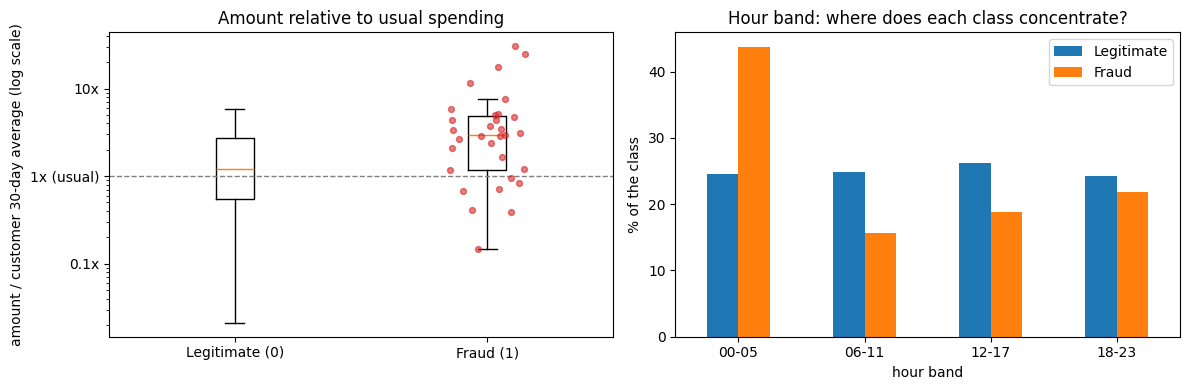

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rng = np.random.default_rng(0)  # fixed seed so the jitter is reproducible

legit = d.loc[d['fraud_flag'] == 0, 'amount_vs_usual'].dropna()
fraud = d.loc[d['fraud_flag'] == 1, 'amount_vs_usual'].dropna()

# Left: amount relative to the customer's usual amount (log scale)
ax[0].boxplot([legit, fraud], showfliers=False)
ax[0].set_xticks([1, 2])
ax[0].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
ax[0].scatter(2 + rng.uniform(-0.15, 0.15, len(fraud)), fraud,
              s=18, alpha=0.6, color='tab:red', zorder=3)   # each red dot = 1 fraud
ax[0].set_yscale('log')
ax[0].set_yticks([0.1, 1, 10])
ax[0].set_yticklabels(['0.1x', '1x (usual)', '10x'])
ax[0].axhline(1, ls='--', color='grey', lw=1)               # 1 = exactly the usual amount
ax[0].set_ylabel('amount / customer 30-day average (log scale)')
ax[0].set_title('Amount relative to usual spending')

# Right: share of each class in every hour band
share = pd.crosstab(d['hour_band'], d['fraud_flag'], normalize='columns') * 100
share.columns = ['Legitimate', 'Fraud']
share.plot.bar(ax=ax[1], rot=0)
ax[1].set_xlabel('hour band')
ax[1].set_ylabel('% of the class')
ax[1].set_title('Hour band: where does each class concentrate?')

plt.tight_layout()
plt.show()

What the tables and plots show (counts in brackets; with 32 frauds, differences between small groups are suggestive, not proven)

- Amount relative to the customer's usual spending is the clearest signal.In the left plot, 1× (dashed line) means "exactly the usual amount" and the axis is logarithmic, so each tick is 10 times the previous one. The median ratio is 2.94 for frauds vs 1.20 for legitimate transactions. Transactions above 2× the usual amount hold 21 of the 31 frauds with a known amount (68%) but only about a third of the rows. The fraud rate rises from about 0.4–0.5% to 1.7–2.2% (above 2×). The raw amount alone identifies few frauds (only 6 of 32 are above the IQR fence, see 2.4), so the *ratio* carries information that the raw amount does not.
- This signal is not a clean separator. The boxes of the two classes overlap, and 7 of the 31 frauds are at or below their customer's usual amount (band "<=1x"). On the other hand, several frauds are 10–30 times the usual amount. It helps to rank risk, but it does not decide on its own.
- Night hours: in the right plot, legitimate transactions are spread evenly over the four hour bands (about 25% each), while 44% of the frauds (14 of 32) happen between 00 and 05 h. The fraud rate of that band is 1.77% (791 rows) vs 0.63–0.90% in the others.
- Country: BE (1.76%) and DE (1.74%) are about 2–4× higher than ES, FR, NL, UK (0.40–0.76%); together they hold 19 of 32 frauds. This may be real or chance; to be treated with caution (country as a feature carries fairness and stability concerns).
- New accounts (≤ 30 days): 4.55% fraud rate, but that is only 2 frauds in 44 rows, too small to rely on.
- Channel shows no clear difference (app 1.13%, online 1.05%, store 0.63%).
- account_age_days, device_age_days, previous_transactions_24h: medians are nearly identical between classes, so they look weak on their own.

### 2.6 Leakage check: columns that may not be known at the decision moment

In [7]:
print('chargeback_confirmed_after_60d vs fraud_flag:')
print(pd.crosstab(df['fraud_flag'], df['chargeback_confirmed_after_60d']))

print('\npost_investigation_loss_eur > 0 vs fraud_flag:')
print(pd.crosstab(df['fraud_flag'], df['post_investigation_loss_eur'] > 0))

print('\nLoss among fraud cases (EUR):')
print(df.loc[df['fraud_flag'] == 1, 'post_investigation_loss_eur'].describe().round(2))

print('\nCorrelation with fraud_flag:')
print(df[['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h',
          'hour', 'device_age_days', 'post_investigation_loss_eur',
          'chargeback_confirmed_after_60d']].corrwith(df['fraud_flag']).round(3))

# Do the legitimate rows ever have a loss or chargeback?
print('\nLegitimate rows with loss > 0 or chargeback = 1:',
      ((df['fraud_flag'] == 0) & ((df['post_investigation_loss_eur'] > 0) | (df['chargeback_confirmed_after_60d'] == 1))).sum())
print('Fraud rows with loss = 0:', ((df['fraud_flag'] == 1) & (df['post_investigation_loss_eur'] == 0)).sum())

chargeback_confirmed_after_60d vs fraud_flag:
chargeback_confirmed_after_60d     0   1
fraud_flag                              
0                               3171   0
1                                  0  32

post_investigation_loss_eur > 0 vs fraud_flag:
post_investigation_loss_eur  False  True 
fraud_flag                               
0                             3171      0
1                                0     32

Loss among fraud cases (EUR):
count     32.00
mean     116.27
std      123.46
min        8.23
25%       40.23
50%       58.72
75%      152.51
max      599.22
Name: post_investigation_loss_eur, dtype: float64

Correlation with fraud_flag:
amount_eur                        0.060
customer_avg_amount_30d          -0.022
account_age_days                  0.013
previous_transactions_24h        -0.003
hour                             -0.031
device_age_days                  -0.012
post_investigation_loss_eur       0.690
chargeback_confirmed_after_60d    1.000
dtype: float64


**What the output shows – leakage**
- "chargeback_confirmed_after_60d" is identical to the target: all 32 frauds have 1 and all 3,171 legitimate rows have 0 (correlation 1.000). It is a copy of the label that is only known 60 days later.
- "post_investigation_loss_eur" is > 0 exactly for the 32 frauds and 0 for every legitimate row (correlation 0.69 because the amount varies). It exists only after an investigation has already decided the case.
- Both columns would give an apparently perfect model that is useless in practice, because at the decision moment (Phase 1) they do not exist yet. They must not be predictors. The formal exclusion decision is made in Phase 3, with this evidence.
- Useful side-information: among frauds, the loss has mean 116.27 EUR and median 58.72 EUR (range 8.23–599.22). We keep this column only for business evaluation in Phase 5 (what a missed fraud costs), never as an input.
- All other variables have weak individual correlation with the target (|r| ≤ 0.06). This warns us that a model will probably have limited ranking power.
- Note on labelling: every fraud has a confirmed chargeback, so "fraud_flag" seems to be defined by confirmed chargebacks. Fraud that was never disputed or detected would appear as legitimate (label noise), so the true fraud rate is probably ≥ 1.0%.

### 2.7 What Phase 2 says about Phase 1 (confirm / challenge / refine)

| Phase 1 statement | Evidence in Phase 2 | Verdict |
|---|---|---|
| Fraud is rare and accuracy is not a valid criterion | 1.00% fraud, 99 legitimate per fraud (2.2) | Confirmed |
| Post-investigation fields are leakage | "chargeback_confirmed_after_60d" = target; loss > 0 only for frauds (2.6) | Confirmed, with evidence |
| The data are about travel bookings | No trip-related column in 2.1 / dictionary | Challenged: generic transaction data |
| "fraud_flag" = true fraud | Every fraud has a confirmed chargeback; undisputed fraud would look legitimate (2.6) | Refined it is chargeback-confirmed fraud; true fraud is probably higher |
| Success = recall at top 5% review capacity | Only 32 frauds, so about 10 in a 30% test set: one fraud = about 10 points of recall | Refined report counts, not only percentages; use a stratified split and consider cross-validation to see if a result is stable |
| Only information known at the decision moment can be used | "customer_avg_amount_30d" and "previous_transactions_24h" are only valid if they exclude the current transaction; the data cannot show this | Refined documented as an assumption/limitation |

### 2.8 Consequences for Phase 3 (evidence: planned decision)
1. Duplicates (3 rows, 2.2): remove before splitting.
2. "channel" inconsistent labels (2.3): standardise to 3 categories.
3. Missing "amount_eur" (20 rows, 2.3): impute using training data only, and keep a missing indicator.
4. Negative "account_age_days" (4 rows, 2.3): treat as invalid (to be decided and justified in Phase 3).
5. Leakage columns (2.6): exclude from predictors; keep the loss column for Phase 5 only.
6. Feature idea supported by 2.5: amount relative to the customer's usual amount (log ratio), and a night-hour indicator.
7. Skewed "amount_eur" (2.4): log transform; do not delete outliers.

## Phase 3 – Data Preparation

Order of work (to prevent leakage).
1. Stateless fixes (duplicates, labels, impossible values, removing leakage columns) are done on the whole table, because they do not learn anything from the data.
2. Stratified train/test split. From then on the test set is sealed: every piece of evidence below is computed on the train set only.
3. Anything that learns from data (medians for missing values, scaling) is fitted on train only and then applied to test.

Honest note: The Phase 2 patterns were observed on all 3,203 rows, which include future test rows. To limit this, the hour bands were fixed in advance as four equal 6-hour blocks (not tuned to the results), and each feature decision below is re-checked on the train set.

Each decision follows the same chain: evidence → technique → before/after check → interpretation → next decision.

### Decision 1 – Clean the data (duplicates, channel labels, negative ages)

#### 1a – Remove the exact duplicate rows
Evidence (2.2): 3 rows are exact copies of an earlier row (same "transaction_id" and values), placed at the end of the file (all 3 are legitimate).
Technique: "drop_duplicates()" before the split. If a copy ended up in test and the original in train, the model would be evaluated on a transaction it has already seen and the result would look better than it is.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

work = df.copy()   # df from Phase 2 stays untouched

print('BEFORE  rows:', len(work), '| unique transaction_id:', work['transaction_id'].nunique(),
      '| frauds:', work['fraud_flag'].sum())
work = work.drop_duplicates()
print('AFTER   rows:', len(work), '| unique transaction_id:', work['transaction_id'].nunique(),
      '| frauds:', work['fraud_flag'].sum())
print('transaction_id is now unique:', work['transaction_id'].is_unique)

BEFORE  rows: 3203 | unique transaction_id: 3200 | frauds: 32
AFTER   rows: 3200 | unique transaction_id: 3200 | frauds: 32
transaction_id is now unique: True


Check and interpretation: 3,203 to 3,200 rows, every "transaction_id" is now unique, and the number of frauds is unchanged (32), so nothing relevant was removed. Next: the inconsistent labels.

#### 1b – Standardise the "channel" labels
Evidence (2.3): 6 labels for 3 real channels ("app/APP", "online/Online/ONLINE", "store").
Technique: lower-case and strip spaces.

In [9]:
print('BEFORE – channel labels (%d):' % work['channel'].nunique())
print(work['channel'].value_counts().to_string())

work['channel'] = work['channel'].str.lower().str.strip()

print('\nAFTER – channel labels (%d):' % work['channel'].nunique())
print(work['channel'].value_counts().to_string())

BEFORE – channel labels (6):
channel
app       1017
online     947
store      636
Online     280
APP        219
ONLINE     101

AFTER – channel labels (3):
channel
online    1328
app       1236
store      636


Check and interpretation: 6 to 3 labels and the counts add up (1,328 + 1,236 + 636 = 3,200). We will see in Decision 4 that "channel" is not used by the model, but it is kept clean because Phase 5 compares errors by segment, and "app" and "APP" would otherwise appear as two different segments.

#### 1c – Treat negative account ages as missing
Evidence (2.3): 4 rows have "account_age_days" between −20 and −28, which is impossible. All 4 are legitimate.
Options considered: (a) delete the rows, (b) set them to 0, (c) take the absolute value, (d) mark them as missing.

Choice: (d). We do not know the real age. Setting 0 would label them "brand-new accounts", the group with the highest fraud rate in Phase 2, so we would invent a risk signal. Taking the absolute value assumes a sign error we cannot prove. Deleting loses legitimate data for no gain. Missing + median imputation is neutral.

In [10]:
bad_age = work['account_age_days'] < 0
print('BEFORE  min account_age_days:', work['account_age_days'].min(), '| negative values:', bad_age.sum(),
      '| missing:', work['account_age_days'].isna().sum())

work.loc[bad_age, 'account_age_days'] = np.nan      # invalid -> missing (imputed later, using train data only)

print('AFTER   min account_age_days:', work['account_age_days'].min(), '| negative values:',
      (work['account_age_days'] < 0).sum(), '| missing:', work['account_age_days'].isna().sum())

BEFORE  min account_age_days: -28 | negative values: 4 | missing: 0
AFTER   min account_age_days: 2.0 | negative values: 0 | missing: 4


Check and interpretation: negatives 4 to 0 and missing 0 to 4; the smallest valid age is now 2 days. The effect is tiny (4 rows, 0.1%) and the imputation itself happens later, fitted on train only (Decision 5).

### Decision 2 – Remove the leakage columns
Evidence (2.6): "chargeback_confirmed_after_60d" is an exact copy of the target and "post_investigation_loss_eur" is > 0 only for frauds. Neither exists at the decision moment defined in Phase 1.

Technique: drop both from the working table (not only from the feature list, so they cannot be used by accident), use "transaction_id" as index (an ID is not a predictor) and keep the loss in a separate series, "loss_eur", "only" to measure the cost of missed fraud in Phase 5.

In [11]:
work = work.set_index('transaction_id')            # the ID identifies rows, it is not a predictor
leak_cols = ['post_investigation_loss_eur', 'chargeback_confirmed_after_60d']

print('BEFORE – correlation with fraud_flag of the leakage columns:')
print(work[leak_cols + ['fraud_flag']].corr()['fraud_flag'].drop('fraud_flag').round(3).to_string())

loss_eur = work['post_investigation_loss_eur'].copy()   # kept aside for the business evaluation in Phase 5 ONLY
work = work.drop(columns=leak_cols)

others = work.select_dtypes('number').drop(columns='fraud_flag')
print('\nAFTER  – columns left:', list(work.columns))
print('Largest |correlation| with fraud_flag among the remaining numeric columns: %.3f'
      % others.corrwith(work['fraud_flag']).abs().max())

BEFORE – correlation with fraud_flag of the leakage columns:
post_investigation_loss_eur       0.69
chargeback_confirmed_after_60d    1.00

AFTER  – columns left: ['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'channel', 'country', 'hour', 'device_age_days', 'fraud_flag']
Largest |correlation| with fraud_flag among the remaining numeric columns: 0.060


Check and interpretation: before, the two columns correlate 1.00 and 0.69 with the target; after, the strongest remaining numeric correlation is 0.060. A model on the remaining columns can no longer "read the answer". This is also why later performance will be modest: it is the honest level of signal available before the decision.
Limit of this check: it only detects direct leakage. The assumption that "customer_avg_amount_30d" and "previous_transactions_24h" exclude the current transaction (Phase 2) cannot be tested with this data.

### Decision 3 – Stratified 70/30 split (the test set is sealed from here)
Technique: "train_test_split"(test_size=0.30, stratify=y, random_state=42).
- Stratified: with around 1% fraud, a plain random split could leave as few as 3 or as many as 17 of the 32 frauds in test. Stratifying keeps the fraud rate equal in both sets.
- Why 30%: gives about 10 test frauds and 22 train frauds. With 20% the test would hold only about 6 frauds (too noisy to evaluate), with 40% only about 19 would remain to learn from. Both sets are small: this is a real limitation. In Phase 4 the model will be chosen with stratified cross-validation inside train, so that the test set is used once, in Phase 5.
- Why random and not by time: the file has no timestamp, so a time-ordered split is not possible. The ID order is only a proxy that we cannot confirm. If fraud patterns drift over time, a random split can make results look better than they will be in practice.

In [12]:
y = work['fraud_flag']
X = work.drop(columns='fraud_flag')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
loss_test = loss_eur.loc[X_test.index]             # loss of each test transaction (Phase 5 only)

summary = pd.DataFrame({'rows': [len(y), len(y_train), len(y_test)],
                        'frauds': [y.sum(), y_train.sum(), y_test.sum()]},
                       index=['all', 'train', 'test'])
summary['fraud_rate_%'] = (100 * summary['frauds'] / summary['rows']).round(2)
print(summary)
print('\nTrain and test share no transaction:', len(set(X_train.index) & set(X_test.index)) == 0)
print('Test set = 5%% review capacity -> about %d transactions to review' % round(0.05 * len(y_test)))

# Is there any sign that fraud is concentrated in one part of the file (ID order)?
id_order = pd.qcut(np.arange(len(y)), 5, labels=['1st fifth', '2nd', '3rd', '4th', '5th'])
print('\nFrauds per fifth of the file (rows ordered by transaction_id):')
print(y.sort_index().groupby(id_order).sum().to_string())

       rows  frauds  fraud_rate_%
all    3200      32          1.00
train  2240      22          0.98
test    960      10          1.04

Train and test share no transaction: True
Test set = 5% review capacity -> about 48 transactions to review

Frauds per fifth of the file (rows ordered by transaction_id):
1st fifth    8
2nd          4
3rd          7
4th          7
5th          6


Check and interpretation: train 2,240 rows (22 frauds, 0.98%) and test 960 rows (10 frauds, 1.04%): both keep the 1.00% rate; no transaction is in both sets. A 5% review capacity on the test set means about 48 reviews, as assumed in Phase 1. Frauds are spread over the file (8, 4, 7, 7, 6 per fifth), so there is no obvious block that a random split would leave out. 

Next: build the features, using train evidence only.

### Decision 4 – Build the feature set

#### 4a – Engineer features
Evidence (train only): see the output below.

In [13]:
# From here on, every piece of evidence is computed on the TRAIN set only
train = X_train.assign(fraud_flag=y_train)
ratio = train['amount_eur'] / train['customer_avg_amount_30d']

print('Skewness BEFORE -> AFTER log transformation (train):')
print('  amount_eur                 : %5.2f -> %5.2f' % (train['amount_eur'].skew(), np.log(train['amount_eur']).skew()))
print('  amount / customer average  : %5.2f -> %5.2f' % (ratio.skew(), np.log(ratio).skew()))

print('\nMedian amount / customer average by class (train):')
print(ratio.groupby(train['fraud_flag']).median().round(2).rename({0: 'legitimate', 1: 'fraud'}).to_string())

print('\nFraud rate by hour group (train):')
train['hour_group'] = np.where(train['hour'] <= 5, '00-05 (night)', '06-23')
t = train.groupby('hour_group')['fraud_flag'].agg(rows='size', frauds='sum')
t['fraud_rate_%'] = (100 * t['frauds'] / t['rows']).round(2)
print(t)

print('\nMissing amount_eur (train): %d rows, of which %d fraud' %
      (train['amount_eur'].isna().sum(), train.loc[train['amount_eur'].isna(), 'fraud_flag'].sum()))

Skewness BEFORE -> AFTER log transformation (train):
  amount_eur                 :  3.88 ->  0.00
  amount / customer average  :  7.73 ->  0.02

Median amount / customer average by class (train):
fraud_flag
legitimate    1.19
fraud         3.15

Fraud rate by hour group (train):
               rows  frauds  fraud_rate_%
hour_group                               
00-05 (night)   541       9          1.66
06-23          1699      13          0.77

Missing amount_eur (train): 11 rows, of which 1 fraud


**Decisions**
- "log_amount_vs_usual"= ln(amount / customer 30-day average). The ratio is the clearest signal (median 3.15 for frauds vs 1.19 for legitimate transactions) but it is extremely skewed (7.73). The logarithm fixes the skew and makes "double the usual" and "half the usual" equally far from "usual".
- "log_amount" = ln(amount). Purchase size on a symmetric scale (skew 3.88 to 0.00).
- "night" = 1 if hour is between 0 and 5. In Phase 2 the fraud rate was higher only between 00 and 05 h and flat afterwards. Hour is circular, so a numeric "hour" with a single linear coefficient would be misleading; one flag captures the effect. On train: 1.66% at night vs 0.77% the rest of the day, about twice, but based on only 9 night frauds, so the evidence is modest.
- Not created, on purpose: a "new_account" flag (only 2 frauds in 44 rows in Phase 2) and the missing-amount indicator planned in 2.8 (only 1 fraud among the 11 missing amounts in train). With so few cases the model could only learn noise from them, so we refine the 2.8 plan: missing amounts are imputed but not flagged.

All features use only the row's own values, so the same function is applied to train and test without leakage.

In [14]:
def make_features(frame):
    """Row-wise features: each row uses only its own values, so applying it to train and test is leak-free."""
    out = frame.copy()
    out['log_amount'] = np.log(out['amount_eur'])
    out['log_amount_vs_usual'] = np.log(out['amount_eur'] / out['customer_avg_amount_30d'])
    out['night'] = (out['hour'] <= 5).astype(int)
    return out

X_train_f = make_features(X_train)
X_test_f = make_features(X_test)

# Verification 1: no information is lost by dropping customer_avg_amount_30d (it can be rebuilt)
rebuilt = np.exp(X_train_f['log_amount'] - X_train_f['log_amount_vs_usual'])
print('customer_avg_amount_30d can be rebuilt from the two new columns:',
      np.allclose(rebuilt.dropna(), X_train_f.loc[rebuilt.notna(), 'customer_avg_amount_30d']))

# Verification 2: the new columns behave as intended
print('\nSkewness of the new columns (train):')
print(X_train_f[['log_amount', 'log_amount_vs_usual']].skew().round(2).to_string())
print('\nShare of night transactions: train %.1f%% | test %.1f%%' %
      (100 * X_train_f['night'].mean(), 100 * X_test_f['night'].mean()))

customer_avg_amount_30d can be rebuilt from the two new columns: True

Skewness of the new columns (train):
log_amount             0.00
log_amount_vs_usual    0.02

Share of night transactions: train 24.2% | test 25.8%


Check and interpretation: "customer_avg_amount_30d" can be rebuilt exactly from the two new columns, so we can drop it and the raw amount without losing information. 
New columns are symmetric (skew 0.00 and 0.02) and the share of night transactions is similar in train (24.2%) and test (25.8%).

#### 4b – Which columns leave the model
Evidence (train only): association of each categorical variable with the target.

In [15]:
# Evidence on the TRAIN set for the categorical variables (chi-square test of independence with fraud_flag)
for col in ['country', 'channel']:
    ct = pd.crosstab(X_train[col], y_train)
    chi2, p, _, _ = chi2_contingency(ct)
    print('%s: p-value = %.3f' % (col, p))
    print(ct.T.rename(index={0: 'legitimate', 1: 'fraud'}).to_string())
    print()

country: p-value = 0.006
country      BE   DE   ES   FR   NL   UK
fraud_flag                              
legitimate  399  349  408  358  373  331
fraud         9    7    1    3    0    2

channel: p-value = 0.656
channel     app  online  store
fraud_flag                    
legitimate  856     920    442
fraud         8      11      3



**Decisions and reasons**
- "channel": excluded. No association with fraud (p = 0.66) and no business mechanism that suggests one.
- "country": excluded from the model (kept for Phase 5). This is the least obvious decision, because on train the association is statistically visible (p = 0.006, BE and DE concentrate 16 of the 22 frauds).
We still leave it out because: 

(1) several cells are almost empty (NL 0 frauds, ES 1, UK 2): the model would learn "NL is never fraud" from zero cases. 

(2) the pattern was found by searching among variables with only 22 frauds, so it may not repeat on new data. 

(3) reviewing customers more often because of their country is a fairness-proxy decision that the risk manager (Phase 1) should take, not something the model should pick up by default. In Phase 5 we will check whether errors and review rates differ by country. If Phase 4 tests a model with country, it must be reported as a comparison, not adopted silently.
- Raw "hour", "amount_eur", "customer_avg_amount_30d": replaced by "night", "log_amount" and "log_amount_vs_usual" (4a).
- "account_age_days", "device_age_days", "previous_transactions_24h": kept. Their medians barely differ between classes (2.5), but they are plausible risk signals (new accounts, new devices, bursts of activity) without stability or fairness problems, the regularisation in Phase 4 will give them little weight if they are useless.

| Original column | Role in the model |
|---|---|
| "transaction_id" | index (identifier) |
| "amount_eur", "customer_avg_amount_30d" | replaced by "log_amount", "log_amount_vs_usual" |
| "hour" | replaced by "night" |
| "account_age_days", "device_age_days", "previous_transactions_24h" | feature (as they are) |
| "channel", "country" | excluded, kept for Phase 5 subgroup analysis |
| "post_investigation_loss_eur" | removed; only for Phase 5 cost evaluation |
| "chargeback_confirmed_after_60d" | removed (leakage) |
| "fraud_flag" | target |

### Decision 5 – Preprocessing fitted on train only
Evidence: missing values remain in the features (train 11 / 11 / 3, test 9 / 9 / 1) and the scales are very different (account age around 1,250 days vs around 2 transactions).
Technique: a "ColumnTransformer": median imputation + standardisation for the continuous features, "night" passes unchanged.
- Median, not mean: robust to skew and extreme values. For the 20 missing amounts (0.6%) a more elaborate imputation is not worth the complexity.
- Standardisation: needed for regularised logistic regression (Phase 4), so that the penalty treats all features equally and coefficients are comparable.
- Built as one object so that Phase 4 can refit it inside every cross-validation fold, fitting it once on the whole train set and then cross-validating would leak information between folds.

In [16]:
continuous = ['log_amount', 'log_amount_vs_usual', 'account_age_days', 'device_age_days', 'previous_transactions_24h']
binary = ['night']
features = continuous + binary

print('Features used by the model (%d): %s' % (len(features), features))
print('Leakage / ID columns inside the feature list:',
      [c for c in features if c in leak_cols + ['transaction_id', 'fraud_flag']])

preprocess = ColumnTransformer([
    ('continuous', Pipeline([('impute', SimpleImputer(strategy='median')),
                             ('scale', StandardScaler())]), continuous),
    ('binary', 'passthrough', binary)])

Xtr, Xte = X_train_f[features], X_test_f[features]

print('\nBEFORE – missing values per feature (train | test):')
print(pd.DataFrame({'train': Xtr.isna().sum(), 'test': Xte.isna().sum()}).query('train > 0 or test > 0').to_string())

preprocess.fit(Xtr)                                 # <- fitted on TRAIN only
Z_train = pd.DataFrame(preprocess.transform(Xtr), columns=features, index=Xtr.index)
Z_test = pd.DataFrame(preprocess.transform(Xte), columns=features, index=Xte.index)

print('\nAFTER  – missing values (train | test):', Z_train.isna().sum().sum(), '|', Z_test.isna().sum().sum())

imp = preprocess.named_transformers_['continuous'].named_steps['impute']
medians = pd.DataFrame({'used by the imputer': imp.statistics_,
                        'train median': Xtr[continuous].median().values,
                        'test median': Xte[continuous].median().values}, index=continuous)
print('\nMedian used to fill gaps = TRAIN median (not the test one):')
print(medians.round(3).to_string())

print('\nScaled continuous features – mean and std:')
print(pd.concat({'train': Z_train[continuous].agg(['mean', 'std']),
                 'test': Z_test[continuous].agg(['mean', 'std'])}).round(3).to_string())

Features used by the model (6): ['log_amount', 'log_amount_vs_usual', 'account_age_days', 'device_age_days', 'previous_transactions_24h', 'night']
Leakage / ID columns inside the feature list: []

BEFORE – missing values per feature (train | test):
                     train  test
log_amount              11     9
log_amount_vs_usual     11     9
account_age_days         3     1

AFTER  – missing values (train | test): 0 | 0

Median used to fill gaps = TRAIN median (not the test one):
                           used by the imputer  train median  test median
log_amount                               4.095         4.095         4.16
log_amount_vs_usual                      0.180         0.180         0.22
account_age_days                      1249.000      1249.000      1268.00
device_age_days                        581.000       581.000       569.50
previous_transactions_24h                2.000         2.000         2.00

Scaled continuous features – mean and std:
            log_amount 

**Check and interpretation:**
- Missing values: 0 in train and test after the transformation.
- Proof that the test set was not used: the imputer uses exactly the train medians, which differ from the test medians (4.16).
- Train features have mean 0 and std 1 by construction; test features are close but not exact: they were scaled with the train statistics.

### 3.9 Leakage audit

| Step | Learns from data? | Fitted on |
|---|---|---|
| Remove duplicates, clean labels, negative age - missing | No | – (rule applied to all rows) |
| Drop leakage columns and ID | No | – |
| Row-wise features ("log_amount", "log_amount_vs_usual", "night") | No (each row uses only its own values) | – |
| Median imputation | Yes | train only |
| Standardisation | Yes | train only |
| Feature choices (Decision 4) | Yes (evidence) | train only, apart from the Phase 2 caveat noted above |

### 3.10 Decision log

| # | Decision | Evidence | Technique | Check |
|---|---|---|---|---|
| 1 | Clean the data (duplicates, "channel" labels, negative ages) | 3 exact copies, 6 labels for 3 channels, 4 impossible ages (2.2, 2.3) | "drop_duplicates" before the split; lower-case + strip; negative age set to NaN, impute later | 3,203 to 3,200 rows, IDs unique; 6 to 3 labels; negatives 4 to 0 |
| 2 | Remove leakage columns | corr 1.00 and 0.69 (2.6) | drop + keep loss aside for Phase 5 | max remaining corr 0.060 |
| 3 | Stratified 70/30 split | 1% fraud, 32 cases | "stratify=y", seed 42 | 22 / 10 frauds, rates 0.98% / 1.04% |
| 4 | Build the feature set | skew 7.73, ratio 3.15 vs 1.19, night 1.66% vs 0.77%; sparse country cells; "channel" p = 0.66 | log ratio, log amount, night flag; exclude "channel", "country", raw "hour" | skew around 0; average rebuildable; 6 features, no leakage |
| 5 | Impute + scale on train only | missing values, different scales | "ColumnTransformer" fitted on train | 0 missing; imputer = train medians |

### 3.11 What Phase 3 hands over to Phase 4
"Z_train", "Z_test", "y_train", "y_test", the unfitted-on-test "preprocess" object, "features", and "loss_test" (for Phase 5). 

Next decisions: baseline (a model that ranks at random / says "all legitimate") and one justified candidate (regularised logistic regression is the natural starting point with 22 training frauds), selected with stratified cross-validation inside train. Limitations carried forward: only 22 frauds to learn from and 10 to test, no timestamp, the label is chargeback-confirmed fraud.